Iteration 1: Best Distance = 206.83
Iteration 2: Best Distance = 206.83
Iteration 3: Best Distance = 206.83
Iteration 4: Best Distance = 206.83
Iteration 5: Best Distance = 206.83
Iteration 6: Best Distance = 206.83
Iteration 7: Best Distance = 206.83
Iteration 8: Best Distance = 206.83
Iteration 9: Best Distance = 206.83
Iteration 10: Best Distance = 206.83
Iteration 11: Best Distance = 206.83
Iteration 12: Best Distance = 206.83
Iteration 13: Best Distance = 206.83
Iteration 14: Best Distance = 206.83
Iteration 15: Best Distance = 206.83
Iteration 16: Best Distance = 206.83
Iteration 17: Best Distance = 206.83
Iteration 18: Best Distance = 206.83
Iteration 19: Best Distance = 206.83
Iteration 20: Best Distance = 206.83
Iteration 21: Best Distance = 206.83
Iteration 22: Best Distance = 206.83
Iteration 23: Best Distance = 206.83
Iteration 24: Best Distance = 206.83
Iteration 25: Best Distance = 206.83
Iteration 26: Best Distance = 206.83
Iteration 27: Best Distance = 206.83
Iteration 

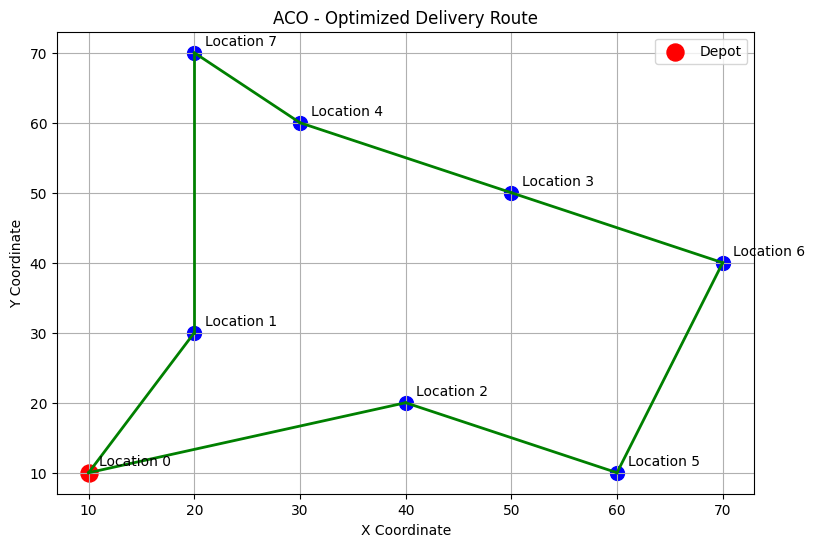

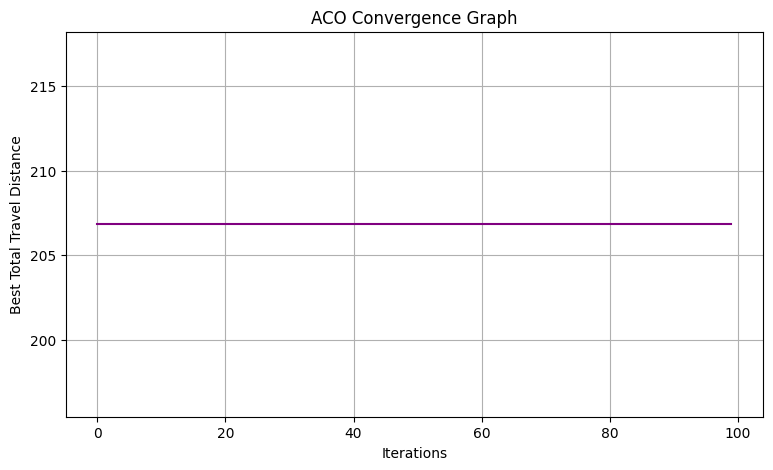

In [8]:

import numpy as np
import random
import matplotlib.pyplot as plt

# -----------------------------------------
# ANT COLONY OPTIMIZATION FOR DELIVERY
# ROUTE OPTIMIZATION
# -----------------------------------------

# Delivery locations (x, y coordinates)
locations = {
    0: (10, 10),  # Depot
    1: (20, 30),
    2: (40, 20),
    3: (50, 50),
    4: (30, 60),
    5: (60, 10),
    6: (70, 40),
    7: (20, 70)
}

num_locations = len(locations)

# ACO parameters
num_ants = 20
num_iterations = 100
alpha = 1.0       # Pheromone importance
beta = 5.0        # Distance importance
evaporation = 0.5
Q = 100

# -----------------------------------------
# STEP 1: CREATE DISTANCE MATRIX
# -----------------------------------------

distance_matrix = np.zeros((num_locations, num_locations))

for i in range(num_locations):
    for j in range(num_locations):
        if i != j:
            x1, y1 = locations[i]
            x2, y2 = locations[j]

            distance_matrix[i][j] = np.sqrt(
                (x2 - x1)**2 + (y2 - y1)**2
            )

# -----------------------------------------
# STEP 2: INITIALIZE PHEROMONES
# -----------------------------------------

pheromone = np.ones((num_locations, num_locations))

# Heuristic information
heuristic = 1 / (distance_matrix + 1e-10)

# -----------------------------------------
# STEP 3: CALCULATE ROUTE DISTANCE
# -----------------------------------------

def calculate_distance(route):
    total_distance = 0

    for i in range(len(route) - 1):
        total_distance += distance_matrix[
            route[i], route[i + 1]
        ]

    return total_distance

# -----------------------------------------
# STEP 4: SELECT NEXT LOCATION
# -----------------------------------------

def select_next_city(current_city, unvisited):

    probabilities = []

    for city in unvisited:

        probability = (
            (pheromone[current_city][city] ** alpha) *
            (heuristic[current_city][city] ** beta)
        )

        probabilities.append(probability)

    probabilities = np.array(probabilities)

    probabilities = probabilities / np.sum(probabilities)

    next_city = random.choices(
        list(unvisited),
        weights=probabilities,
        k=1
    )[0]

    return next_city

# -----------------------------------------
# STEP 5: CONSTRUCT ANT ROUTES
# -----------------------------------------

def construct_route():

    route = [0]  # Start from depot

    unvisited = set(range(1, num_locations))

    while unvisited:

        current_city = route[-1]

        next_city = select_next_city(
            current_city, unvisited
        )

        route.append(next_city)

        unvisited.remove(next_city)

    route.append(0)  # Return to depot

    return route

# -----------------------------------------
# STEP 6: UPDATE PHEROMONES
# -----------------------------------------

def update_pheromones(all_routes, all_distances):

    global pheromone

    # Evaporation
    pheromone *= (1 - evaporation)

    # Deposit pheromones
    for route, distance in zip(all_routes, all_distances):

        deposit = Q / distance

        for i in range(len(route) - 1):

            city1 = route[i]
            city2 = route[i + 1]

            pheromone[city1][city2] += deposit
            pheromone[city2][city1] += deposit

# -----------------------------------------
# STEP 7: MAIN ACO ALGORITHM
# -----------------------------------------

best_route = None
best_distance = float('inf')

convergence = []

for iteration in range(num_iterations):

    all_routes = []
    all_distances = []

    for ant in range(num_ants):

        route = construct_route()

        distance = calculate_distance(route)

        all_routes.append(route)
        all_distances.append(distance)

        if distance < best_distance:

            best_distance = distance
            best_route = route.copy()

    update_pheromones(all_routes, all_distances)

    convergence.append(best_distance)

    print(
        f"Iteration {iteration + 1}: "
        f"Best Distance = {best_distance:.2f}"
    )

# -----------------------------------------
# STEP 8: DISPLAY RESULTS
# -----------------------------------------

print("\n========== FINAL RESULTS ==========")

print("Best Delivery Route:", best_route)

print("Minimum Total Travel Distance:",
      round(best_distance, 2))

# -----------------------------------------
# STEP 9: VISUALIZE BEST DELIVERY ROUTE
# -----------------------------------------

plt.figure(figsize=(9, 6))

for city, (x, y) in locations.items():

    if city == 0:
        plt.scatter(x, y, color='red', s=150,
                    label='Depot')
    else:
        plt.scatter(x, y, color='blue', s=100)

    plt.text(x + 1, y + 1, f"Location {city}")

for i in range(len(best_route) - 1):

    city1 = best_route[i]
    city2 = best_route[i + 1]

    x1, y1 = locations[city1]
    x2, y2 = locations[city2]

    plt.plot(
        [x1, x2],
        [y1, y2],
        'g-',
        linewidth=2
    )

plt.title("ACO - Optimized Delivery Route")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend()
plt.grid(True)
plt.show()

# -----------------------------------------
# STEP 10: CONVERGENCE GRAPH
# -----------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(convergence, color='purple')

plt.title("ACO Convergence Graph")
plt.xlabel("Iterations")
plt.ylabel("Best Total Travel Distance")

plt.grid(True)
plt.show()
